# **Thames Valley Crime Data Analysis**
## EDA: Exploratory Data Analysis
---

### Objectives

- Use the cleaned dataset from `01_ETL.ipynb` to answer Key Analytical Questions 1-3 (see below).
- Describe the basic characteristics of the data: averages, spread, distributions, outliers and correlations.
- Find which crime types are most common, how crime differs between the 13 areas and whether crime has risen or fallen over the 36 months.
- Explore the seasonal pattern (if any), ready for the statistical test in `03_statistical_testing.ipynb`.
- Decide which charts to rebuild for the Streamlit dashboard.

### Planned Steps

1. Load and check the cleaned data
2. Descriptive statistics, distributions, outliers and correlations
3. Question 1 - Which crimes are the most common?
4. Question 2 - How does crime differ between the 13 areas?
5. Question 3 - Has crime risen or fallen over the 36 months?
6. Question 4 - Is there a seasonal pattern? (charts only)
7. Conclusions
8. Decide on charts to rebuild for the dashboard, and next steps

### Inputs

`../data/clean/crime_summary.csv` - Crime counts per month, season, area and crime type.

The summary file is used rather than `crime_clean.csv`, because all the questions here are about **how many** crimes there are. It is much smaller (0.3 MB), so it is quicker to load.

### Key Questions explored in this notebook

1. Which reported crime types are the most common across the Thames Valley?
2. How does crime differ between the 13 areas?
3. Has the number of crimes risen or fallen between October 2023 and September 2026?

**Explored here with charts; the statistical test is in `03_statistical_testing.ipynb`**

4. Is there a seasonal pattern, and if so is the difference between summer and winter statistically different?

**Will be answered in `04_modelling.ipynb`**

5. Can monthly crime counts be predicted for an area and crime type, if so which model does it best?

### Outputs

- Summary statistics, distributions, outliers and correlations.
- Charts and findings for Key Questions 1-3.
- Seasonal charts for Key Question 4.

### Additional Comments

- Cells in this notebook run top to bottom.
- All figures are **counts**, not **rates**. Larger areas naturally have more crime (see Limitations in the README).
---

### Setup

Import required libraries:

- `pandas` - to load and group the data.
- `matplotlib` and `seaborn` - to draw charts.

Note: `%matplotlib inline` is used so charts display inside the notebook (see Bugs in README).

In [1]:
# Import required libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Ensures that charts are displayed in the notebook
%matplotlib inline

print("Libraries imported successfully")

Libraries imported successfully


---
### 1. Load and check the cleaned data

Here we will load and check the summary data from `01_ETL.ipynb` to make sure nothing was lost or changed when it was saved.

In [2]:
summary = pd.read_csv("../data/clean/crime_summary.csv")
summary.head()


,Month,Season,Area,Crime type,Count
0,2023-10-01,Autumn,Bracknell Forest,Anti-social behaviour,81
1,2023-10-01,Autumn,Buckinghamshire,Anti-social behaviour,306
2,2023-10-01,Autumn,Cherwell,Anti-social behaviour,90
3,2023-10-01,Autumn,Milton Keynes,Anti-social behaviour,171
4,2023-10-01,Autumn,Oxford,Anti-social behaviour,125


In [3]:
# Check the data type of each column
summary.dtypes

Month         object
Season        object
Area          object
Crime type    object
Count          int64
dtype: object

***Month*** shows as `object`, which means it has been read as text. This is because a CSV stores everything as text, so the date format from the ETL notebook was lost when the file was saved. We need to convert it back to a date using `pd.to_datetime`.

***Season***, ***Area***, and ***Crime type*** are text, ***Count*** is a whole number (`int64`) - so these are correct.

In [4]:
# Convert month back to a date
summary['Month'] = pd.to_datetime(summary['Month'])

# Check the conversion
summary.dtypes

Month         datetime64[ns]
Season                object
Area                  object
Crime type            object
Count                  int64
dtype: object

***Month*** is now showing in the correct format, and ready to use.

Quick checks to make sure the loaded file matches what was exported in `01_ETL.ipynb`:

In [5]:
# Check number of rows (should be 6,552)
print("Rows:", len(summary))

# Check the number of columns (should be 5)
print("Columns:", len(summary.columns))

# Check the column names (should be Month, Season, Area, Crime type and Count)
print("Column Names:", summary.columns.tolist())

# Add the count column for each row (should total 579,772)
print("Total crimes:", summary["Count"].sum())

# Check number of months, areas and crime types (should be 36, 13 and 14)
print("Number of Months:", summary["Month"].nunique())
print("Number of Areas:", summary["Area"].nunique())
print("Number of Crime Types:", summary["Crime type"].nunique())

# Check for any missing values in the dataset
print("Total Missing Values:", summary.isnull().sum().sum())


Rows: 6552
Columns: 5
Column Names: ['Month', 'Season', 'Area', 'Crime type', 'Count']
Total crimes: 579772
Number of Months: 36
Number of Areas: 13
Number of Crime Types: 14
Total Missing Values: 0


All checks match the data exported from `01_ETL.ipynb`: 6,552 rows, 5 columns, correct column names, 579,772 crimes, 36 months, 13 areas and 14 crime types. 

There are no missing values, and no data was lost when it was saved. The only change was the ***Month*** date format, which has now been converted back.

The data is now ready for analysis.

---

### 2. Descriptive statistics, distributions, outliers and correlations

Before answering the key questions, we need to look at the basic characteristics of the data: the average, how spread out it is, its shape, anything unusual, and whether crime types rise and fall together, or move in opposite directions. 

#### Summary Statistics

The *mode*, *median* and *mean* are measures of **central tendency**: three ways of finding out the middle or the typical value of the data.

**Mean**: the average (add up all the values and divide by how many there are).

**Median**: the middle value when all the values are put in order. It is not pulled up or down by a few very big or small values.

**Mode**: the value that appears most often.

##### Which should we use?

**Mean**: when there are no outliers

**Median**: when there are outliers

**Mode**: for category data (such as crime type)

<br>

**Standard deviation**: how spread out the values are from the mean. The smaller the deviation, the closer the values are to the mean. 

**Variance**: the standard deviation squared. It measures the same thing as standard deviation, but in a different way (in squared units, which is why standard deviation is easier to read).

In [6]:
# Three ways to find the middle of the count column
print("Mean:", round(summary["Count"].mean(), 1))
print("Median:", summary["Count"].median())
print("Mode:", summary["Count"].mode()[0])


Mean: 88.5
Median: 43.0
Mode: 5


The mean (88.5) is around twice the median (43). When the mean is much higher than the median, it could be that a few large values are pulling the average up, which would mean the data is right-skewed.

The mode is 5, so the most common count is small.

A histogram and outlier check will establish if this is true.

Next, we need to check the **standard deviation** and **variance**, which are measures of **variability**. They show how spread out the counts are. Using minimum and maximum in our code will allow us to see the full range.

In [7]:
# Explore the distribution of crime counts
print("Standard deviation:", round(summary["Count"].std(), 1))
print("Variance:", round(summary["Count"].var(), 1))
print("Minimum:", summary["Count"].min())
print("Maximum:", summary["Count"].max())
print("Range:", summary["Count"].max() - summary["Count"].min())

Standard deviation: 143.4
Variance: 20576.5
Minimum: 0
Maximum: 1384
Range: 1384


The standard deviation (143.4) is much larger than the mean (about 1.6 times), indicating the counts are very spread out. The counts range from 0 to 1,384 crimes.

A minimum of 0 shows that some crime types had none reported in an area for at least one of the months, while the maximum of 1,384 is far higher than the median of 43. This also suggests that the data is right-skewed.

Below we can find out how many rows have 0 crimes reported.

In [8]:
# Count how many rows have zero crimes
zero_rows = (summary["Count"] == 0).sum()
print("Rows with zero crimes:", zero_rows)
print("Percentage of rows with zero crimes:", round(zero_rows / len(summary) * 100, 2), "%")

Rows with zero crimes: 28
Percentage of rows with zero crimes: 0.43 %


Only 28 rows (equating to 0.43%) have zero crimes, so almost every crime type is recorded in every area each month. With only 28 zero counts out of 6,552 rows, they are rare and should not affect the analysis or modelling.

A histogram shows the shape of the data, allowing us to see which counts are common and which are rare. The blue line is a smoothed outline of the bars, which makes the overall shape easier to see. The dashed lines mark the mean and the median.

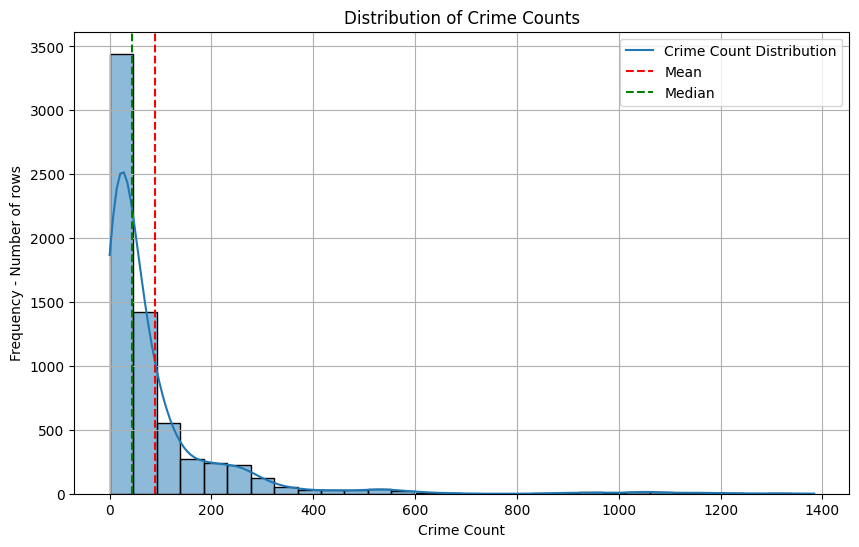

In [9]:
# Histogram of count distribution with mean and median lines
plt.figure(figsize=(10, 6))
sns.histplot(summary, x="Count", bins=30, kde=True)
plt.grid(True)
plt.axvline(summary["Count"].mean(), color='r', linestyle='--', label='Mean')
plt.axvline(summary["Count"].median(), color='g', linestyle='--', label='Median')
plt.title("Distribution of Crime Counts")
plt.xlabel("Crime Count")
plt.ylabel("Frequency - Number of rows")
plt.legend(["Crime Count Distribution", "Mean", "Median"])
plt.show()

The histogram confirms that the data is **right-skewed**. Most counts are small (the tallest bar is in the lowest range), with a long tail of large counts stretching up to 1,384 (see the variability statistics above).

The median (green line) sits to the left of the mean (red line), because the few very large counts pull the mean up. This confirms that the **median** is the better measure of a typical value for this dataset.

A few counts are much larger than the rest, and these are what pull the mean up. The outlier check below will show how many there are and where they come from.

#### Outliers

An **outlier** is a count that is much higher or lower than the rest of the data.

We could not check for the outliers in `01_ETL.ipynb`, because the raw data had one row per crime and no counts. The ***Count*** column only exists after the data was summarised at the end of the notebook, so we check for outliers here.

To find them, we use the **IQR** (interquartile range). This is the range covered by the middle half of the counts. A count is a possible outlier if it is more than 1.5 times the IQR above the top of that middle half.

A count can't be less than 0 (as you can't have a negative number of crimes), so we only need to check for very high counts.

First, we find the quartiles. These split the counts in order from smallest to largest, then into four equal parts.
- **Q1** (25th percentile): a quarter of the counts are below this value
- **Q2** (50th percentile): the middle value, which is the median (43)
- **Q3** (75th percentile): three quarters of the counts are below this value.

The **IQR** (Q3 minus Q1) is the range covered by the middle part of the counts.

In [10]:
# Work out the quartiles
q1 = summary["Count"].quantile(0.25)
q3 = summary["Count"].quantile(0.75)
iqr = q3 - q1

print("Q1 (25th percentile):", q1)
print("Q3 (75th percentile):", q3)
print("Interquartile Range (IQR):", iqr)

Q1 (25th percentile): 16.0
Q3 (75th percentile): 95.0
Interquartile Range (IQR): 79.0


1/4 of the counts are 16 or fewer, and 3/4 are 95 or fewer. That means the middle half of the counts fall between 16 and 95, giving an IQR of 79.

Next, we work out the lower and upper limits, any count below the lower limit or above the upper limit is a possible outlier.

After that we need to establish where the outliers come from.

In [11]:
# Calculate the lower and upper limits for outliers
lower_limit = q1 - 1.5 * iqr
upper_limit = q3 + 1.5 * iqr

print("Lower Limit for Outliers:", lower_limit)
print("Upper Limit for Outliers:", upper_limit)

Lower Limit for Outliers: -102.5
Upper Limit for Outliers: 213.5


The lower limit is below 0, and a count can't be negative, so there are no low outliers. We now know only counts above 213.5 are possible outliers.

Next, we find out the rows that sit above the upper limit.

In [12]:
# Find the rows above the upper limit for outliers
outliers = summary[summary["Count"] > upper_limit]
print("Rows above the upper limit for outliers:", len(outliers))
print("Percentage of Rows:", str(round(len(outliers) / len(summary) * 100, 2)) + "%")

Rows above the upper limit for outliers: 703
Percentage of Rows: 10.73%


703 rows (10.73%) are above the upper limit of 213.5. This is a large share for outliers, which suggests that some crime types are much more common than others, rather than these being errors. Before we do anything or make any assumptions, we should first check which crime types they come from.

The table below will show how many of the outliers come from each crime type. Then we will work out what percentage of the outliers come from the three highest crime types.

In [13]:
# Count the outliers for each crime type
outlier_types = outliers["Crime type"].value_counts().reset_index()
outlier_types.columns = ["Crime type", "Number of outliers"]
outlier_types["Percentage of outliers"] = round(outlier_types["Number of outliers"] / len(outliers) * 100, 2)

outlier_types

,Crime type,Number of outliers,Percentage of outliers
0,Violence and sexual offences,447,63.58
1,Shoplifting,83,11.81
2,Anti-social behaviour,58,8.25
3,Other theft,38,5.41
4,Public order,33,4.69
5,Criminal damage and arson,30,4.27
6,Vehicle crime,14,1.99


In [14]:
# Share of outliers from the top 3 crime types
top_three = outlier_types["Number of outliers"].head(3).sum()
print("Top three crime types:", top_three, "of", len(outliers), "outliers")
print("Percentage:", round(top_three / len(outliers) * 100, 2), "%")

Top three crime types: 588 of 703 outliers
Percentage: 83.64 %


Only 7 of the 14 crime types have outliers. The rest always stay below the limit.

Violence and sexual offences makes up 447 of the outliers (63.58%). Like every crime type, it has 468 rows (36 months x 13 areas), so its count is above the limit in almost every area and month. This shows these are not unusual values; it is simply the most commonly recorded crime type thus the monthly counts are higher than any other crime type.

The next largest are Shoplifting (83 outliers, 11.81%) and Anti-social behaviour (58 outliers, 8.25%). Together with Violence and sexual offences, these three make up 83.64% (588 of 703) of all outliers. The remaining four crime types only have a small number of outliers each.

The box plots below will show the outliers visually. The box is the middle half of the counts (Q1 to Q3), the line inside it is the median, and each dot is a possible outlier. The red dashed line marks the outlier limit of 213.5.

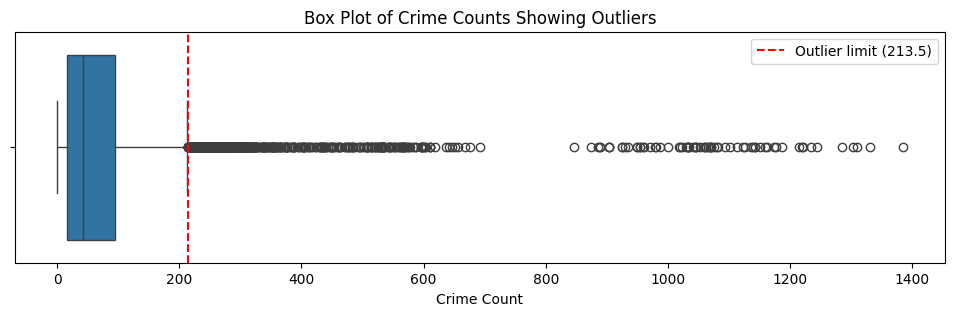

In [15]:
# Box plot of crime counts showing outliers
plt.figure(figsize=(12, 3))
sns.boxplot(data=summary, x="Count")
plt.axvline(upper_limit, color="r", linestyle="--", label="Outlier limit (213.5)")
plt.title("Box Plot of Crime Counts Showing Outliers")
plt.xlabel("Crime Count")
plt.legend()
plt.show()

The box plot above shows how small the box is compared with the long line of dots to its right. Most counts are low, and the outliers stretch from the limit (213.5) up to 1,384 (which we found out earlier). There is also a gap between about 700 and 850, with a separate group of very high counts above it.

To see where the outliers come from, the second box plot shows one box per crime type, ordered from the highest median to the lowest.

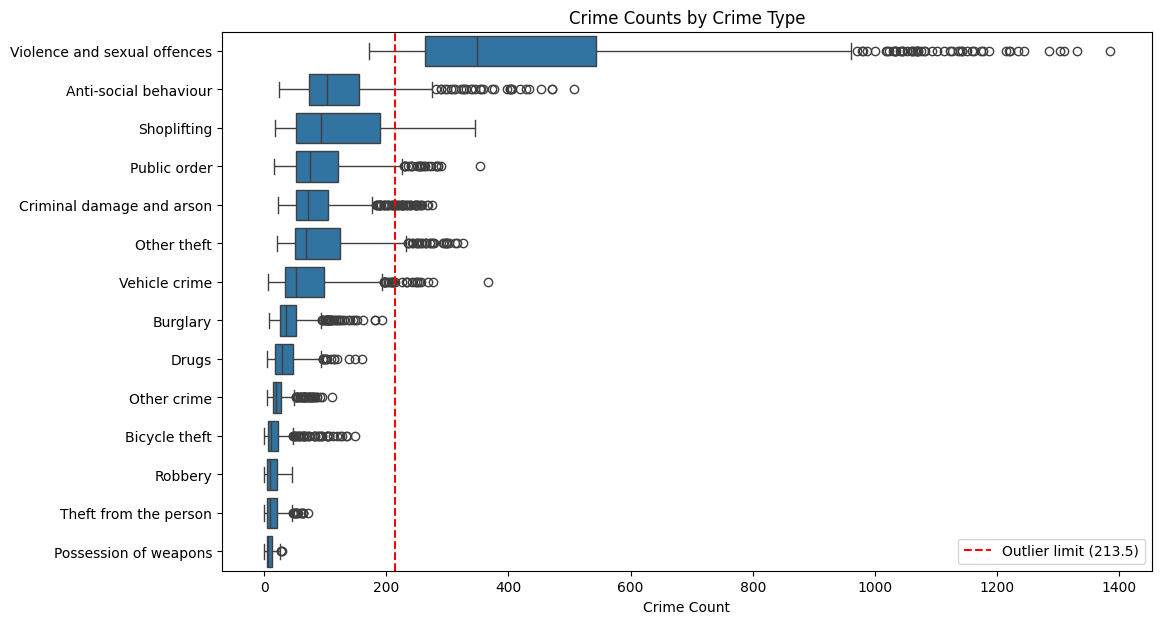

In [16]:
# One box per crime type, ordered from highest to lowest median
order = summary.groupby("Crime type")["Count"].median().sort_values(ascending=False).index

plt.figure(figsize=(12, 7))
sns.boxplot(data=summary, x="Count", y="Crime type", order=order)
plt.axvline(upper_limit, color="r", linestyle="--", label="Outlier limit (213.5)")
plt.title("Crime Counts by Crime Type")
plt.xlabel("Crime Count")
plt.ylabel("")
plt.legend()
plt.show()

This shows clearly why there are so many outliers. **Violence and sexual offences** sits almost entirely to the right of the outlier limit. Its typical month (the median) is higher than the limit itself. Its highest counts (around 850 to 1,384) make up the separate group of very high counts found in the first box plot.

**Anti-social behaviour**, **Shoplifting**, **Public order**, **Criminal damage and arson**, **Other theft**, and **Vehicle crime** mostly sit below the limit. Their boxes are to the left of the red line, and only their highest counts cross it. These are the same six crime types in the outlier table above, with between 14 (Vehicle crime) and 83 (Shoplifting) outliers each.

The remaining seven crime types (**Burglary**, **Drugs**, **Other crime**, **Bicycle theft**, **Robbery**, **Theft from the person** and **Possession of weapons**) stay completely below the limit, so they have no outliers. Some of them still have dots on the chart, but these are high compared with that crime type, not with the whole dataset.

<br>

#### Conclusion and decision on outliers

Together, the two box plots and the outlier table show that the 703 outliers are not likely to be errors. Most of them come from one crime type, **Violence and sexual offences**, which is simply recorded far more than any other crime type.

With the above in mind, the outliers will be kept. They appear to be real recorded crimes, and most of them come from **Violence and sexual offences**. The data shows its normal level, not errors. If we were to remove them we would be removing the most important figures for the police.

#### Correlations

Now that we have explored the spread of the counts and where the outliers come from, the next step is to check whether different crime types rise and fall together over time.

**Correlation** measures how closely two things move together, on a scale of -1 to 1.

- **Close to 1:** when one goes up, the other usually goes up too.
- **Close to 0:** there is no clear link.
- **Close to -1:** when one goes up, the other usually goes down.

However, correlation does not prove that one causes the other. For example, two crime types might both rise in summer without being connected.

<br>

To demonstrate this, first we need to reshape the data so there is one row for each month, and one column for each crime type, with each cell holding the total crimes across all areas.

This will allow us to compare how each crime type changes from month to month.

In [17]:
# One row per month, one column per crime type
crime_by_month = summary.pivot_table(index="Month", columns="Crime type", values="Count", aggfunc="sum")

# Display number of rows and columns and the head of the pivot table
print("Rows (months) and columns (crime types):", crime_by_month.shape)
crime_by_month.head()

Rows (months) and columns (crime types): (36, 14)


Crime type,Anti-social behaviour,Bicycle theft,Burglary,Criminal damage and arson,Drugs,Other crime,Other theft,Possession of weapons,Public order,Robbery,Shoplifting,Theft from the person,Vehicle crime,Violence and sexual offences
Month,,,,,,,,,,,,,,
2023-10-01,1523,397,725,1269,396,280,1411,133,1332,143,1298,250,1207,6443
2023-11-01,1315,261,721,1150,442,302,1299,127,1141,120,1409,267,1214,5995
2023-12-01,979,212,649,1130,418,243,1271,113,1039,118,1289,256,1153,5761
2024-01-01,1125,216,719,1068,389,321,1224,126,1060,111,1426,243,1333,5896
2024-02-01,1214,177,597,1138,419,305,1220,127,1038,109,1345,219,1153,5621


The heatmap below shows the correlation between the between every pair of crime types. Red sqaures are close to 1 (they move together), blue squares are close to -1 (they move in opposite directions), and pale squires are close to 0 (no clear link)

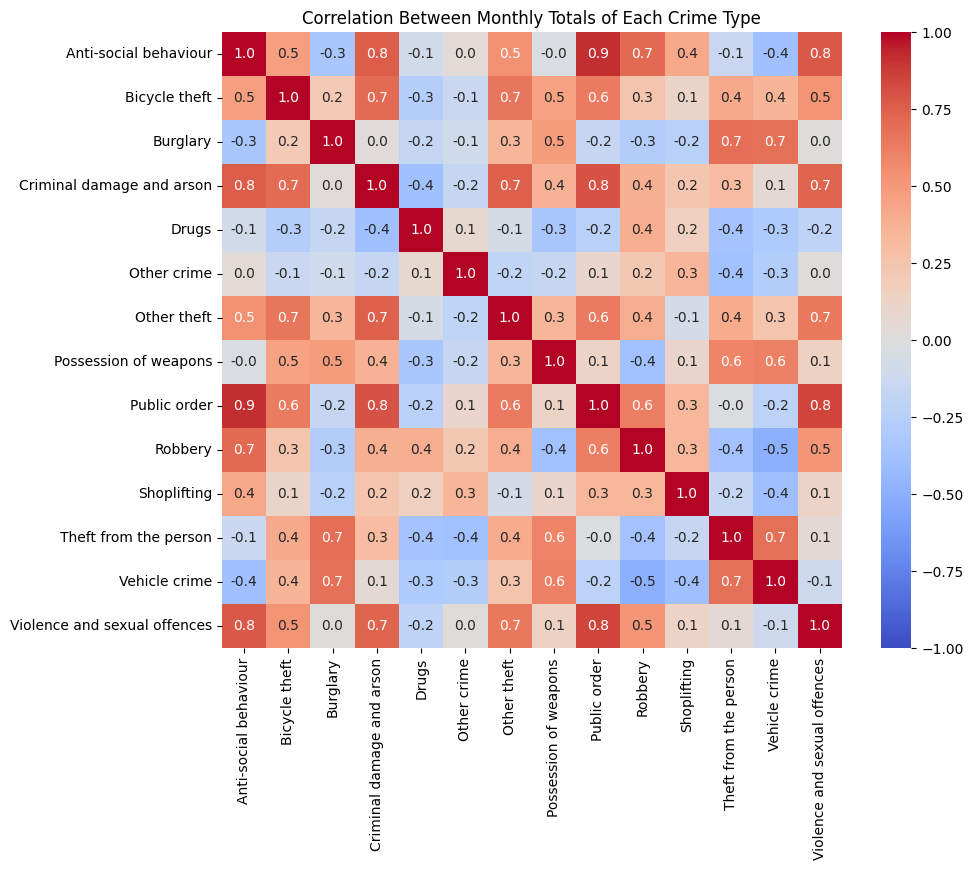

In [18]:
# Heatmap of the correlation between every pair of crime types by month
plt.figure(figsize=(10, 8))
sns.heatmap(crime_by_month.corr(), annot=True, fmt=".1f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation Between Monthly Totals of Each Crime Type")
plt.xlabel("")
plt.ylabel("")
plt.show()

The heatmap shows two main groups of crime types that rise and fall together:
- **Anti-social behaviour, Public order, Violence and sexual offences** and **Criminal damage and arson** are strongly linked (0.7 to 0.9). The strongest link is between **Anti-social behaviour** and **Public order** (0.9).
- **Burglary, Theft from the person** and **Vehicle crime** form a second group (0.7 between each pair).

There are no strong negative correlations: the lowest is -0.5 (**Robbery and Vehicle crime**). **Drugs, Other crime** and **Shoplifting** have only weak links with every other crime type (between -0.4 and 0.4), so they follow their own pattern.

As correlation does not prove cause, these groups may simply share the same pattern over the year, such as rising in the same season. Key Question 4 looks at the seasons in more detail.

#### Findings - Descriptive statistics

- **Typical value:** the mean (88.5) is about twice the median (43), so a few very large counts pull the average up. The **median** is the better measure here.
- **Spread and shape:** counts range from 0 to 1,384, with a standard deviation (143.4) larger than the mean. The histogram confirms the data is **right-skewed**.
- **Outliers:** 703 rows (10.73%) are above the limit of 213.5, mostly **Violence and sexual offences**. These are real crime levels, not errors, so they are **kept**.
- **Correlations:** two groups of crime types move together: Anti-social behaviour, Public order, Violence and sexual offences, and Criminal damage and arson (0.7 to 0.9), and Burglary, Theft from the person and Vehicle crime (0.7). Drugs, Other crime and Shoplifting follow their own pattern.

---
### 3. Question 1 - Which crimes are the most common?

To answer this, we will add up the ***Count*** for each crime type across all 13 areas and 36 months, then work out each crime type's share of all crimes.

This links back to the **mode**: for category data such as crime type, the most common value is the mode. In this case, the crime type with the highest total count is the mode, representing the most frequently occurring crime across the dataset.

In [19]:
# Total crimes for each crime type
crime_types = summary.groupby("Crime type")["Count"].sum().sort_values(ascending=False)
crime_types

Crime type
Violence and sexual offences    217946
Anti-social behaviour            60597
Shoplifting                      56883
Other theft                      45768
Public order                     44893
Criminal damage and arson        42491
Vehicle crime                    35381
Burglary                         21188
Drugs                            17124
Other crime                      11493
Bicycle theft                     9400
Theft from the person             6669
Robbery                           5886
Possession of weapons             4053
Name: Count, dtype: int64

The totals show which crime types are recorded the most often. To make them easier to compare, we will turn them into a table and add each crime type's percentage of all crimes.

After that, we can look at the % share of the top 3 and the bottom 3 crime types.

In [20]:
# Turn the totals into a table with a percentage column
crime_types = crime_types.reset_index()
crime_types["Percentage"] = (crime_types["Count"] / crime_types["Count"].sum() * 100).round(2)

crime_types

,Crime type,Count,Percentage
0,Violence and sexual offences,217946,37.59
1,Anti-social behaviour,60597,10.45
2,Shoplifting,56883,9.81
3,Other theft,45768,7.89
4,Public order,44893,7.74
5,Criminal damage and arson,42491,7.33
6,Vehicle crime,35381,6.10
7,Burglary,21188,3.65
8,Drugs,17124,2.95
9,Other crime,11493,1.98


In [21]:
# Share of all crime from the top 3 crime types
print("Total share of top three crime types:", round(crime_types["Percentage"].head(3).sum(), 2), "%")

# Share of all crime from the bottom 3 crime types
print("Total share of bottom three crime types:", round(crime_types["Percentage"].tail(3).sum(), 2), "%")

Total share of top three crime types: 57.85 %
Total share of bottom three crime types: 2.87 %


We can show the above more clearly in a horizontal barchart.

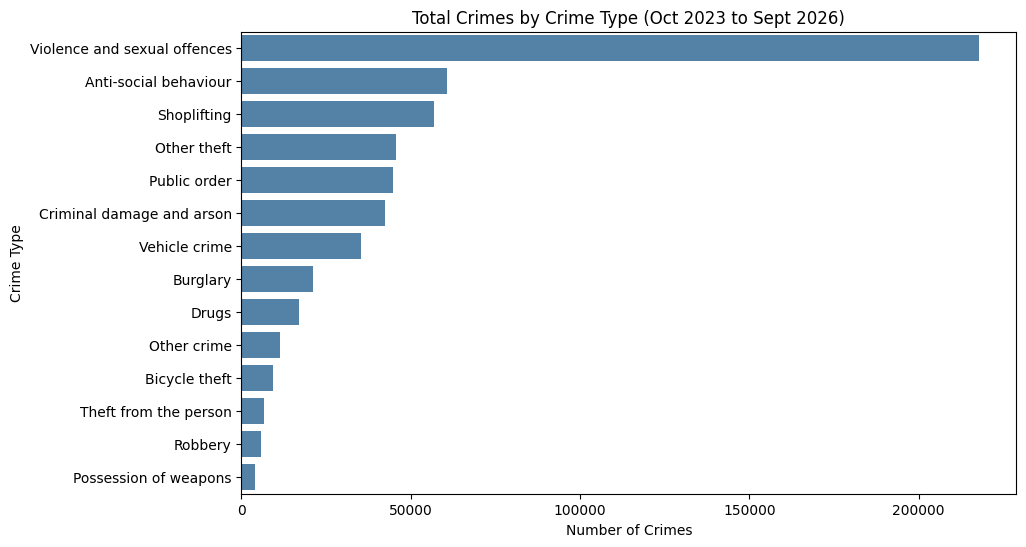

In [22]:
# Horizontal bar chart of total crimes by crime type
plt.figure(figsize=(10, 6))
sns.barplot(data=crime_types, x="Count", y="Crime type", color="steelblue")
plt.title("Total Crimes by Crime Type (Oct 2023 to Sept 2026)")
plt.xlabel("Number of Crimes")
plt.ylabel("Crime Type")
plt.show()

#### Findings - Question 1

From the results above we can clearly see:
- **Violence and sexual offences** is by far the most common crime type, with 217,946 crimes recorded (37.59% of all crime). This is more than three times higher than the next highest, **Anti-social behaviour** (60,597, 10.45%).

- The top 3 crime types (**Violence and sexual offences**, **Anti-social behaviour** and **Shoplifting**) make up 57.85% of all recorded crime over 36 months, which is more than half.

- The least common crime types are **Possession of weapons** (4,053, 0.7%), **Robbery** (5,886, 1.02%) and **Theft from the person** (6,669, 1.15%). Together they make up only 2.87% of all crime.

#### Conclusion
- **Violence and sexual offences** is the **mode** of the crime types.

- The top three crime types (**Violence and sexual offences**, **Anti-social behaviour** and **Shoplifting**) are also the same crime types that made up most of the outliers in Section 2, which confirms they are simply the most commonly recorded crimes.

Note: As we discovered in `01_ETL.ipynb`, Violence and sexual offences is slightly under-counted by area, because more of these crimes had no location and were removed. However, this does not change the result.

---
### 4. Question 2 - How does crime differ between the 13 areas?

We will look at this in two different ways to discover how crime differs between the 13 areas the Thames Valley Police cover.
1. The **total** crimes in each area, to see where most crime is recorded.
2. The **mix** of crime types in each area, to see whether some areas have a bigger share of certain crimes.

#### Total crimes by area

First, we add up the ***Count*** for each area across all of the 36 months and crime types, then work out each area's share of all the crimes reported.

In [23]:
# Total crimes for each area, with percentages
areas = summary.groupby("Area")["Count"].sum().sort_values(ascending=False).reset_index()
areas["Percentage"] = (areas["Count"] / areas["Count"].sum() * 100).round(2)

areas

,Area,Count,Percentage
0,Buckinghamshire,107913,18.61
1,Milton Keynes,90251,15.57
2,Reading,59777,10.31
3,Oxford,54340,9.37
4,Slough,50706,8.75
5,Cherwell,36832,6.35
6,West Berkshire,32641,5.63
7,Windsor and Maidenhead,31291,5.40
8,Bracknell Forest,26195,4.52
9,Wokingham,25956,4.48


From the results, we can see that **Buckinghamshire** records the most crime (107,913, 18.61%), followed by **Milton Keynes** (90,251, 15.57%).

We can also see that **West Oxfordshire** records the least crime (17,626, 3.04%), followed by **South Oxfordshire** (22,319, 3.85%).

A bubble map will help us visualise where crime is concentrated across the Thames Valley. Each bubble is placed at the centre of its area. The bigger the bubble, the more crimes were recorded there.

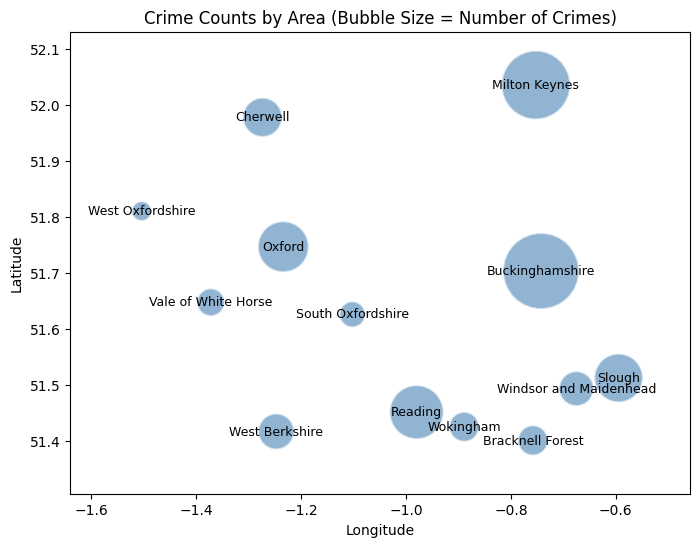

In [34]:
# Load the centre point of each area and join it to the totals
locations = pd.read_csv("../data/clean/area_locations.csv")
area_map = areas.merge(locations, on="Area")

# Bubble map
plt.figure(figsize=(8,6))
sns.scatterplot(data=area_map, x="Longitude", y="Latitude", size="Count", legend=False, sizes=(200, 3000), alpha=0.6, color="steelblue")

# Label each bubble with area name
for i, row in area_map.iterrows():
    plt.text(row["Longitude"], row["Latitude"], row["Area"], ha="center", va="center", fontsize=9)

plt.title("Crime Counts by Area (Bubble Size = Number of Crimes)")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.margins(0.15)
plt.show()

The largest bubbles are in the north and east of the region (Buckinghamshire and Milton Keynes), and in the south-east (Reading and Slough).

The smallest bubbles are mainly in the west of the region (West Oxfordshire, Vale of White Horse and South Oxfordshire), which are more rural areas.

These are counts, not rates, so larger areas with more people are more likely to record more crime.

#### Mix of crime types in each area

Total counts mostly reflect the size of each area. A fairer way to compare areas is to look at the **mix** of crime (what percentage of each area's crime is each crime type).

To show this, we need to reshape the data so there is one row for each area and one column for each crime type, with each cell holding the total crimes.

In [ ]:
# Reshape one row per area, one column per crime type
area_mix = summary.pivot_table(index="Area", columns="Crime type", values="Count", aggfunc="sum")
area_mix.head()

Crime type,Anti-social behaviour,Bicycle theft,Burglary,Criminal damage and arson,Drugs,Other crime,Other theft,Possession of weapons,Public order,Robbery,Shoplifting,Theft from the person,Vehicle crime,Violence and sexual offences
Area,,,,,,,,,,,,,,
Bracknell Forest,3489,354,815,1884,655,536,1916,141,1906,212,2860,195,1525,9707
Buckinghamshire,11533,596,4217,8293,3265,2570,9434,678,8477,994,8380,906,7391,41179
Cherwell,3307,343,1294,2529,913,849,2974,265,2875,306,4694,308,1611,14564
Milton Keynes,8819,913,3127,6435,2512,1581,6685,655,6699,1041,9383,838,6217,35346
Oxford,4419,3159,1818,3358,2148,825,4710,455,4349,619,7017,1452,2404,17607


Next, we divide each row by that area's total, so every row adds up to 100%. The columns are then put in order from most to the least common crime type (from Question 1). 

In [41]:
# Turn each row into percentages of that area's total
area_mix = area_mix.div(area_mix.sum(axis=1), axis=0) * 100

# Order the columns
area_mix = area_mix[crime_types["Crime type"]]

area_mix.round(2)

Crime type,Violence and sexual offences,Anti-social behaviour,Shoplifting,Other theft,Public order,Criminal damage and arson,Vehicle crime,Burglary,Drugs,Other crime,Bicycle theft,Theft from the person,Robbery,Possession of weapons
Area,,,,,,,,,,,,,,
Bracknell Forest,37.06,13.32,10.92,7.31,7.28,7.19,5.82,3.11,2.50,2.05,1.35,0.74,0.81,0.54
Buckinghamshire,38.16,10.69,7.77,8.74,7.86,7.68,6.85,3.91,3.03,2.38,0.55,0.84,0.92,0.63
Cherwell,39.54,8.98,12.74,8.07,7.81,6.87,4.37,3.51,2.48,2.31,0.93,0.84,0.83,0.72
Milton Keynes,39.16,9.77,10.40,7.41,7.42,7.13,6.89,3.46,2.78,1.75,1.01,0.93,1.15,0.73
Oxford,32.40,8.13,12.91,8.67,8.00,6.18,4.42,3.35,3.95,1.52,5.81,2.67,1.14,0.84
Reading,34.70,10.03,14.20,8.39,7.59,6.37,5.26,3.30,2.38,1.57,2.26,1.73,1.51,0.71
Slough,38.60,9.77,6.46,7.55,7.82,7.41,9.18,3.22,2.95,1.60,1.62,1.38,1.50,0.94
South Oxfordshire,39.97,11.30,7.55,7.93,7.51,8.54,5.21,4.37,2.45,2.53,0.74,0.67,0.58,0.65
Vale of White Horse,40.97,12.20,6.55,7.02,8.64,8.72,3.46,3.76,3.31,2.22,1.09,0.77,0.59,0.70


 The heatmap below shows each area's mix of crime. Darker squares mean a bigger share of that area's crime. Reading down each column shows whether an area has a higher or lower share of a crime type than others.

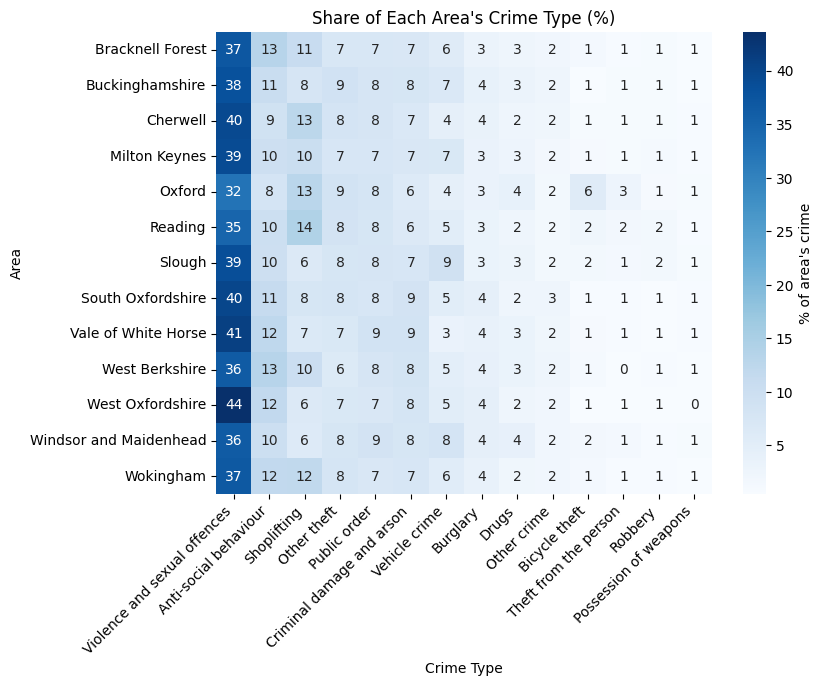

In [47]:
# Draw a Heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(area_mix, annot=True, fmt=".0f", cmap="Blues", cbar_kws={"label": "% of area's crime"})
plt.title("Share of Each Area's Crime Type (%)")
plt.xlabel("Crime Type")
plt.ylabel("Area")
plt.xticks(rotation=45, ha="right")
plt.show()

#### Findings and conclusion - Question 2

Crime does differ in the 13 areas in two main ways:

**How much:**
- **Buckinghamshire** (18.61%) and **Milton Keynes** (15.57%) record the most crime.
- **West Oxfordshire** (3.04%) and **South Oxfordshire** (3.85%) record the least crime.

**Which types:**
- Every area has a similar overall mix of crime, with **Violence and sexual offences** the largest everywhere (ranging from 32% in **Oxford** to 44% in **West Oxfordshire**).
- Some crime types stand out in particular areas:
    - **Shoplifting** in Reading (14%), Oxford (13%) and Cherwell (13%).
    - **Bicycle theft** in Oxford 6% (at least 3 times higher than anywhere else).
    - **Vehicle crime** in Slough and Windsor and Maidenhead (8 to 9%).

- The busiest areas record the most crime, likely due to them being bigger areas with a higher population, so totals alone are not a truly fair comparison.
- Looking at the mix shows each area has its own pattern, which could help the police target specific crime types in specific areas (as documented above).

---
### 5. Question 3 - Has crime risen or fallen over the 36 months?

Now we will look at the monthly trend, comparing each of the three years of data that we have, and see which crimes have changed the most.

To do this we will label each month (October to September) as year 1, 2 or 3 - Each year has 12 months, so the totals can be compared fairly.
Then, work out the total crimes per year and the percentage change from the previous year.

In [53]:
# Label each month with the correct year
def crime_year(month):
    if month < pd.Timestamp("2024-10-01"):
        return "Year 1"
    elif month < pd.Timestamp("2025-10-01"):
        return "Year 2"
    else:
        return "Year 3"

summary["Year"] = summary["Month"].apply(crime_year)

# Total crimes per year with percentage from previous year
yearly = summary.groupby("Year")["Count"].sum().reset_index()
yearly["Percentage Change"] = (yearly["Count"].pct_change() * 100).round(3)

yearly

,Year,Count,Percentage Change
0,Year 1,193853,NaN
1,Year 2,192661,-0.615
2,Year 3,193258,0.310


Year 1 shows a missing value because there is no earlier year to compare it with.

Total crime has stayed fairly consistent across the three years: 193,853 in Year 1, 192,661 in Year 2 (down by 0.615%) and 193,258 in Year 3 (up by 0.310%).

<br>

To answer our key question, we should now look at the overall change from year 1 to year 3.

In [ ]:
# Overall change from Year 1 to Year 3
year1 = yearly["Count"].iloc[0]
year3 = yearly["Count"].iloc[2]
print("(Year 1 to 3) Difference in number of crimes:", year3 - year1)
print("Change from year 1 to Year 3:", round((year3 - year1) / year1 * 100, 3), "%")

(Year 1 to 3) Difference in number of crimes: -595
Change from year 1 to Year 3: -0.307 %


From October 2023 to September 2026 total crime fell by just 0.307% (equating to 595 fewer reported crimes), so overall the crime across the Thames Valley has stayed fairly consistent. It dipped slightly in year 2, then rose again in year 3.

Note: Rounding was changed to 3 decimal places for clarity of there being a difference, due to both initially being rounded up to 0.31% using two decimal places.